<a href="https://colab.research.google.com/github/mia1996/rlcard-tutoirial/blob/master/blackjack_dqn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# <a href='https://github.com/datamllab/rlcard'> <center> <img src='https://miro.medium.com/max/1000/1*_9abDpNTM9Cbsd2HEXYm9Q.png' width=500 class='center' /></a> 

## **Deep-Q Learning on Blackjack**
This example is to use Deep-Q learning to train an agent on Blackjack. We aim to use this example to show how reinforcement learning algorithms can be developed and applied in our toolkit. To be self-contained, we first install RLCard.

In [1]:
!pip install rlcard[torch]


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Now we import `rlcard` and `DQNAgent`. The `DQNAgent` will learn how to win the game.

In [4]:
import rlcard
from rlcard.agents import DQNAgent

Let's create the Blackjack environment and take a look at it.

In [5]:
env = rlcard.make("blackjack")
print("Number of actions:", env.num_actions)
print("Number of players:", env.num_players)
print("Shape of state:", env.state_shape)
print("Shape of action:", env.action_shape)

Number of actions: 2
Number of players: 1
Shape of state: [[2]]
Shape of action: [None]


Blackjack is a very simple game with only two possible actions. There is only one player. It's time for us to train our DQN to master this game! We first create a DQNAgent.

In [6]:
agent = DQNAgent(
    num_actions=env.num_actions,
    state_shape=env.state_shape[0],
    mlp_layers=[64,64],
)

Here, we use a 64-64 deep neural network to learn. Then we pass the DQNAgent to the environment.

In [7]:
env.set_agents([agent])

Now we are ready to train! We first import some useful classes and functions for training.

In [8]:
from rlcard.utils import (
    tournament,
    reorganize,
    Logger,
    plot_curve,
)

Then start the training and log the performance with our `Logger`. The script below will train DQN for 1000 epochs (i.e., 1000 games). Usually, the agent will become stronger if trained longer.

In [10]:
with Logger("experiments/blackjack_dqn_result/") as logger:
    for episode in range(1000):

        # Generate data from the environment
        trajectories, payoffs = env.run(is_training=True)

        # Reorganaize the data to be state, action, reward, next_state, done
        trajectories = reorganize(trajectories, payoffs)

        # Feed transitions into agent memory, and train the agent
        for ts in trajectories[0]:
            agent.feed(ts)

        # Evaluate the performance.
        if episode % 50 == 0:
            logger.log_performance(
                env.timestep,
                tournament(
                    env,
                    10000,
                )[0]
            )

    # Get the paths
    csv_path, fig_path = logger.csv_path, logger.fig_path

INFO - Step 1359, rl-loss: 0.6122584342956543
----------------------------------------
  episode      |  238708
  reward       |  -0.0745
----------------------------------------
INFO - Step 1435, rl-loss: 0.55591392517089843
----------------------------------------
  episode      |  252261
  reward       |  -0.0835
----------------------------------------
INFO - Step 1505, rl-loss: 0.60158354043960577
----------------------------------------
  episode      |  265267
  reward       |  -0.072
----------------------------------------
INFO - Step 1571, rl-loss: 0.44691535830497746
----------------------------------------
  episode      |  278814
  reward       |  -0.092
----------------------------------------
INFO - Step 1648, rl-loss: 0.49553832411766056
----------------------------------------
  episode      |  292174
  reward       |  -0.0645
----------------------------------------
INFO - Step 1721, rl-loss: 0.70777803659439097
----------------------------------------
  episode      

Now we plot the learning curves to monitor how the agent gets improved!

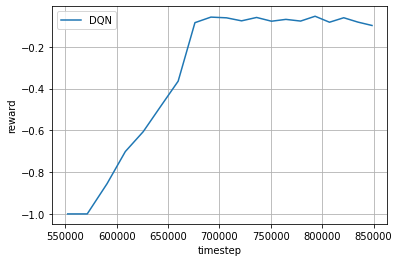

In [ ]:
plot_curve(csv_path, fig_path, "DQN")

You can find that the agent achieves an increasingly better performance with more training. All the logs and the model weights are saved in `experiments/leduc_holdem_dqn_result/`. Now you have your trained DQN agent on Blackjack!